In [2]:

%pip install numpy pandas matplotlib scikit-learn openpyxl


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    RocCurveDisplay,
    make_scorer
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
df = pd.read_excel("classification_escalation.xlsx")

display(df.head())

,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0


Inspecting the dataset

In [7]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Distribution:")
print(df["escalated"].value_counts())

print("\nTarget Proportions:")
print(df["escalated"].value_counts(normalize=True))

Dataset Shape: (900, 6)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   complexity_score        900 non-null    int64  
 1   team_experience_years   869 non-null    float64
 2   priority                882 non-null    str    
 3   channel                 900 non-null    str    
 4   customer_tenure_months  878 non-null    float64
 5   escalated               900 non-null    int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 42.3 KB

Statistical Summary:


,complexity_score,team_experience_years,customer_tenure_months,escalated
count,900.000000,869.000000,878.000000,900.000000
mean,5.433333,4.443268,22.553075,0.206667
std,2.834909,2.137840,14.888236,0.405139
min,1.000000,0.000000,0.900000,0.000000
25%,3.000000,2.900000,11.400000,0.000000
50%,5.000000,4.400000,19.550000,0.000000
75%,8.000000,5.900000,30.150000,0.000000
max,10.000000,11.800000,97.400000,1.000000



Missing Values:
complexity_score           0
team_experience_years     31
priority                  18
channel                    0
customer_tenure_months    22
escalated                  0
dtype: int64

Target Distribution:
escalated
0    714
1    186
Name: count, dtype: int64

Target Proportions:
escalated
0    0.793333
1    0.206667
Name: proportion, dtype: float64


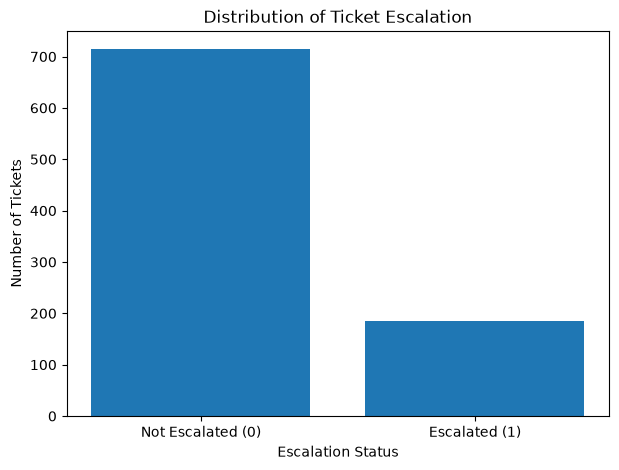

In [8]:
target_counts = df["escalated"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    ["Not Escalated (0)", "Escalated (1)"],
    target_counts.values
)

plt.title("Distribution of Ticket Escalation")
plt.xlabel("Escalation Status")
plt.ylabel("Number of Tickets")

plt.show()

In [23]:
# Separate features and target
X = df.drop("escalated", axis=1)
y = df["escalated"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (900, 5)
y shape: (900,)


Features (X): The input variables that help the model make predictions.
Target (y): The output variable that the model is expected to predict.
The model learns the relationship between X and y.
Removes the escalated column from the dataset.

Why? Because we don't want to give the correct answer to the model as an input. The model must learn to predict it using the other five features.

axis=1 means we are removing a column.

In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (675, 5)
Testing features: (225, 5)
Training target: (675,)
Testing target: (225,)


In [29]:
numeric_features = [
    "complexity_score",
    "team_experience_years",
    "customer_tenure_months"
]

categorical_features = [
    "priority",
    "channel"
]

Preprocessing

In [30]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing completed!")

Preprocessing completed!


In [31]:
models = {
    "Majority Baseline": Pipeline(steps=[
        ("classifier", DummyClassifier(strategy="most_frequent"))
    ]),

    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]),

    "LDA": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", LinearDiscriminantAnalysis())
    ]),

    "k-NN (k=15)": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(n_neighbors=15))
    ])
}

In [32]:
results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    probabilities = model.predict_proba(X_test)
    positive_index = list(model.classes_).index(1)

    auc = roc_auc_score(
        y_test,
        probabilities[:, positive_index]
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": auc
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Majority Baseline,0.7956,0.00,0.0000,0.0000,0.5000
1,Logistic Regression,0.8222,0.75,0.1957,0.3103,0.8111
2,LDA,0.8222,0.75,0.1957,0.3103,0.8090
3,k-NN (k=15),0.7956,0.50,0.0870,0.1481,0.7046


Training data (75%)

Used to teach the machine learning model.

The model studies patterns and relationships between the features and target.

Testing data (25%)

Used to evaluate how well the trained model predicts data it has not seen during training.
Why do we need testing data?
Imagine you are preparing for an examination.
- Training data is like the questions and examples you use to study.
- Testing data is like a new examination that checks whether you actually understood the subject.
If we train and test using exactly the same data, we cannot reliably determine whether the model can generalize to new tickets.

In [33]:
results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    probabilities = model.predict_proba(X_test)
    positive_index = list(model.classes_).index(1)

    auc = roc_auc_score(
        y_test,
        probabilities[:, positive_index]
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": auc
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Majority Baseline,0.7956,0.00,0.0000,0.0000,0.5000
1,Logistic Regression,0.8222,0.75,0.1957,0.3103,0.8111
2,LDA,0.8222,0.75,0.1957,0.3103,0.8090
3,k-NN (k=15),0.7956,0.50,0.0870,0.1481,0.7046


[[176   3]
 [ 37   9]]


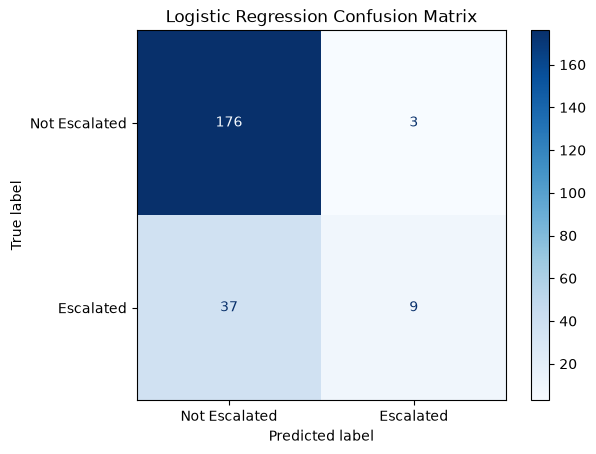

              precision    recall  f1-score   support

           0       0.83      0.98      0.90       179
           1       0.75      0.20      0.31        46

    accuracy                           0.82       225
   macro avg       0.79      0.59      0.60       225
weighted avg       0.81      0.82      0.78       225



In [34]:
logistic_model = models["Logistic Regression"]

y_pred_logistic = logistic_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    y_pred_logistic,
    labels=[0, 1]
)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Escalated", "Escalated"]
).plot(cmap="Blues")

plt.title("Logistic Regression Confusion Matrix")
plt.show()

print(classification_report(
    y_test,
    y_pred_logistic,
    zero_division=0
))

<Figure size 700x500 with 0 Axes>

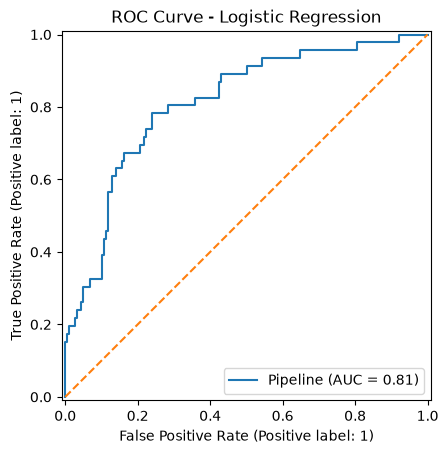

In [35]:
plt.figure(figsize=(7, 5))

RocCurveDisplay.from_estimator(
    logistic_model,
    X_test,
    y_test
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("ROC Curve - Logistic Regression")

plt.show()

In [36]:
y_prob = logistic_model.predict_proba(X_test)[:, 1]

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

for threshold in thresholds:

    y_threshold_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_threshold_pred,
        labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_test, y_threshold_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_threshold_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_threshold_pred, zero_division=0
    )

    cost = 5 * fn + fp

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "FP": fp,
        "FN": fn,
        "Cost": cost
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1,FP,FN,Cost
0,0.2,0.4286,0.7826,0.5538,48,10,98
1,0.3,0.5490,0.6087,0.5773,23,18,113
2,0.4,0.5714,0.2609,0.3582,9,34,179
3,0.5,0.7500,0.1957,0.3103,3,37,188
4,0.6,1.0000,0.0652,0.1224,0,43,215
5,0.7,0.0000,0.0000,0.0000,0,46,230


In [37]:
best_threshold_row = threshold_df.loc[
    threshold_df["Cost"].idxmin()
]

print("Best Threshold:")
print(best_threshold_row)

print("Minimum Cost:", best_threshold_row["Cost"])

Best Threshold:
Threshold     0.200000
Precision     0.428571
Recall        0.782609
F1            0.553846
FP           48.000000
FN           10.000000
Cost         98.000000
Name: 0, dtype: float64
Minimum Cost: 98.0


In [38]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0)
}

cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    cv_results.append({
        "Model": name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Mean Precision": scores["test_precision"].mean(),
        "Mean Recall": scores["test_recall"].mean(),
        "Mean F1": scores["test_f1"].mean()
    })

cv_df = pd.DataFrame(cv_results)

display(cv_df.round(4))

,Model,Mean Accuracy,Mean Precision,Mean Recall,Mean F1
0,Majority Baseline,0.7926,0.0000,0.0000,0.0000
1,Logistic Regression,0.7970,0.5393,0.1643,0.2479
2,LDA,0.8000,0.5543,0.1786,0.2661
3,k-NN (k=15),0.7881,0.4583,0.1000,0.1596


In [39]:
knn_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier())
])

param_grid = {
    "classifier__n_neighbors": [5, 9, 15, 21, 31]
}

grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best CV F1:")
print(grid_search.best_score_)

display(pd.DataFrame(grid_search.cv_results_)[
    ["param_classifier__n_neighbors", "mean_test_score"]
])

Best Parameters:
{'classifier__n_neighbors': 5}
Best CV F1:
0.24329611908559276


,param_classifier__n_neighbors,mean_test_score
0,5,0.243296
1,9,0.197611
2,15,0.159565
3,21,0.145790
4,31,0.112219


In [42]:
p = 0.30

FP_cost = 1
FN_cost = 5

cost_escalate = (1 - p) * FP_cost

cost_not_escalate = p * FN_cost

cost_sensitive_threshold = FP_cost / (FP_cost + FN_cost)

print("Cost of Escalating:", cost_escalate)

print("Cost of Not Escalating:", cost_not_escalate)

print("Cost-sensitive Threshold:", cost_sensitive_threshold)

if cost_escalate < cost_not_escalate:
    print("Decision: Escalate")
else:
    print("Decision: Do Not Escalate")

Cost of Escalating: 0.7
Cost of Not Escalating: 1.5
Cost-sensitive Threshold: 0.16666666666666666
Decision: Escalate


In [43]:
print("MODEL COMPARISON")
display(results_df.round(4))

print("\nCROSS VALIDATION")
display(cv_df.round(4))

print("\nTHRESHOLD RESULTS")
display(threshold_df.round(4))

print("\nBEST K-NN")
print(grid_search.best_params_)

print("\nBEST THRESHOLD")
print(best_threshold_row["Threshold"])

print("\nMINIMUM COST")
print(best_threshold_row["Cost"])

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Majority Baseline,0.7956,0.00,0.0000,0.0000,0.5000
1,Logistic Regression,0.8222,0.75,0.1957,0.3103,0.8111
2,LDA,0.8222,0.75,0.1957,0.3103,0.8090
3,k-NN (k=15),0.7956,0.50,0.0870,0.1481,0.7046



CROSS VALIDATION


,Model,Mean Accuracy,Mean Precision,Mean Recall,Mean F1
0,Majority Baseline,0.7926,0.0000,0.0000,0.0000
1,Logistic Regression,0.7970,0.5393,0.1643,0.2479
2,LDA,0.8000,0.5543,0.1786,0.2661
3,k-NN (k=15),0.7881,0.4583,0.1000,0.1596



THRESHOLD RESULTS


,Threshold,Precision,Recall,F1,FP,FN,Cost
0,0.2,0.4286,0.7826,0.5538,48,10,98
1,0.3,0.5490,0.6087,0.5773,23,18,113
2,0.4,0.5714,0.2609,0.3582,9,34,179
3,0.5,0.7500,0.1957,0.3103,3,37,188
4,0.6,1.0000,0.0652,0.1224,0,43,215
5,0.7,0.0000,0.0000,0.0000,0,46,230



BEST K-NN
{'classifier__n_neighbors': 5}

BEST THRESHOLD
0.2

MINIMUM COST
98.0


## 1.2 Classification Problem

This is a binary classification problem because the target variable
`escalated` has two possible outcomes: 0 and 1.

- 0: The service ticket is not escalated (negative class).
- 1: The service ticket is escalated (positive class).

The positive class is 1 because the main objective is to identify
tickets that require escalation.

The input features include complexity_score, team_experience_years,
priority, channel, and customer_tenure_months.

The model uses these features to learn patterns from previous tickets
and predict whether a new ticket will be escalated.

The dataset is imbalanced because 79.33% of tickets are not escalated,
while only 20.67% are escalated.